<a href="https://colab.research.google.com/github/mynameisBhagya/ids-cicids2017/blob/main/01_CICIDS2017_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import glob
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving WebAttacks-Thursday-no-metadata.parquet to WebAttacks-Thursday-no-metadata.parquet
Saving DoS-Wednesday-no-metadata.parquet to DoS-Wednesday-no-metadata.parquet
Saving Infiltration-Thursday-no-metadata.parquet to Infiltration-Thursday-no-metadata.parquet
Saving Portscan-Friday-no-metadata.parquet to Portscan-Friday-no-metadata.parquet
Saving Bruteforce-Tuesday-no-metadata.parquet to Bruteforce-Tuesday-no-metadata.parquet
Saving DDoS-Friday-no-metadata.parquet to DDoS-Friday-no-metadata.parquet
Saving Benign-Monday-no-metadata.parquet to Benign-Monday-no-metadata.parquet
Saving Botnet-Friday-no-metadata.parquet to Botnet-Friday-no-metadata.parquet


In [4]:
import os

parquet_files = [
    filename
    for filename in uploaded.keys()
    if filename.lower().endswith(".parquet")
]

print("Number of Parquet files uploaded:", len(parquet_files))

for filename in parquet_files:
    print(filename, "-", round(os.path.getsize(filename) / (1024 * 1024), 2), "MB")

Number of Parquet files uploaded: 8
WebAttacks-Thursday-no-metadata.parquet - 16.84 MB
DoS-Wednesday-no-metadata.parquet - 65.04 MB
Infiltration-Thursday-no-metadata.parquet - 22.07 MB
Portscan-Friday-no-metadata.parquet - 12.96 MB
Bruteforce-Tuesday-no-metadata.parquet - 44.0 MB
DDoS-Friday-no-metadata.parquet - 24.13 MB
Benign-Monday-no-metadata.parquet - 54.14 MB
Botnet-Friday-no-metadata.parquet - 18.94 MB


In [5]:
import pandas as pd
import pyarrow.parquet as pq

dataframes = []

for filename in parquet_files:
    print("Reading:", filename)

    df_temp = pd.read_parquet(filename)
    dataframes.append(df_temp)

df = pd.concat(dataframes, ignore_index=True)

print("\nAll 8 files combined successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

display(df.head())

Reading: WebAttacks-Thursday-no-metadata.parquet
Reading: DoS-Wednesday-no-metadata.parquet
Reading: Infiltration-Thursday-no-metadata.parquet
Reading: Portscan-Friday-no-metadata.parquet
Reading: Bruteforce-Tuesday-no-metadata.parquet
Reading: DDoS-Friday-no-metadata.parquet
Reading: Benign-Monday-no-metadata.parquet
Reading: Botnet-Friday-no-metadata.parquet

All 8 files combined successfully!
Total rows: 2313810
Total columns: 78


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,113095465,48,24,9668,10012,403,0,201.416672,203.548294,...,32,203985.500,5.758372e+05,1629110,379,13800000.0,4277541.0,16500000,6737603,Benign
1,6,113473706,68,40,11364,12718,403,0,167.117645,171.919418,...,32,178326.875,5.034269e+05,1424245,325,13800000.0,4229413.0,16500000,6945512,Benign
2,0,119945515,150,0,0,0,0,0,0.000000,0.000000,...,0,6909777.500,1.170000e+07,20400000,6,24400000.0,24300000.0,60100000,5702188,Benign
3,6,60261928,9,7,2330,4221,1093,0,258.888885,409.702148,...,20,0.000,0.000000e+00,0,0,0.0,0.0,0,0,Benign
4,17,269,2,2,102,322,51,51,51.000000,0.000000,...,32,0.000,0.000000e+00,0,0,0.0,0.0,0,0,Benign


In [6]:
print("Columns containing 'label':")

for column in df.columns:
    if "label" in column.lower():
        print(column)

Columns containing 'label':
Label


In [7]:
print(df["Label"].value_counts())

Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [8]:
print("Dataset loaded:", "df" in globals())

if "df" in globals():
    print("Total rows:", df.shape[0])
    print("Total columns:", df.shape[1])
    print("\nFirst 5 rows:")
    display(df.head())

Dataset loaded: True
Total rows: 2313810
Total columns: 78

First 5 rows:


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,113095465,48,24,9668,10012,403,0,201.416672,203.548294,...,32,203985.500,5.758372e+05,1629110,379,13800000.0,4277541.0,16500000,6737603,Benign
1,6,113473706,68,40,11364,12718,403,0,167.117645,171.919418,...,32,178326.875,5.034269e+05,1424245,325,13800000.0,4229413.0,16500000,6945512,Benign
2,0,119945515,150,0,0,0,0,0,0.000000,0.000000,...,0,6909777.500,1.170000e+07,20400000,6,24400000.0,24300000.0,60100000,5702188,Benign
3,6,60261928,9,7,2330,4221,1093,0,258.888885,409.702148,...,20,0.000,0.000000e+00,0,0,0.0,0.0,0,0,Benign
4,17,269,2,2,102,322,51,51,51.000000,0.000000,...,32,0.000,0.000000e+00,0,0,0.0,0.0,0,0,Benign


In [9]:
df.columns = df.columns.str.strip()

print("Column names cleaned.")
print("Total columns:", len(df.columns))

for column in df.columns:
    print(column)

Column names cleaned.
Total columns: 78
Protocol
Flow Duration
Total Fwd Packets
Total Backward Packets
Fwd Packets Length Total
Bwd Packets Length Total
Fwd Packet Length Max
Fwd Packet Length Min
Fwd Packet Length Mean
Fwd Packet Length Std
Bwd Packet Length Max
Bwd Packet Length Min
Bwd Packet Length Mean
Bwd Packet Length Std
Flow Bytes/s
Flow Packets/s
Flow IAT Mean
Flow IAT Std
Flow IAT Max
Flow IAT Min
Fwd IAT Total
Fwd IAT Mean
Fwd IAT Std
Fwd IAT Max
Fwd IAT Min
Bwd IAT Total
Bwd IAT Mean
Bwd IAT Std
Bwd IAT Max
Bwd IAT Min
Fwd PSH Flags
Bwd PSH Flags
Fwd URG Flags
Bwd URG Flags
Fwd Header Length
Bwd Header Length
Fwd Packets/s
Bwd Packets/s
Packet Length Min
Packet Length Max
Packet Length Mean
Packet Length Std
Packet Length Variance
FIN Flag Count
SYN Flag Count
RST Flag Count
PSH Flag Count
ACK Flag Count
URG Flag Count
CWE Flag Count
ECE Flag Count
Down/Up Ratio
Avg Packet Size
Avg Fwd Segment Size
Avg Bwd Segment Size
Fwd Avg Bytes/Bulk
Fwd Avg Packets/Bulk
Fwd Avg Bulk 

In [10]:
label_candidates = [
    column for column in df.columns
    if column.strip().lower() == "label"
]

print("Possible label columns:", label_candidates)

Possible label columns: ['Label']


In [11]:
label_column = label_candidates[0]

print("Selected label column:", label_column)
print("\nTraffic categories:")
print(df[label_column].value_counts(dropna=False))

Selected label column: Label

Traffic categories:
Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


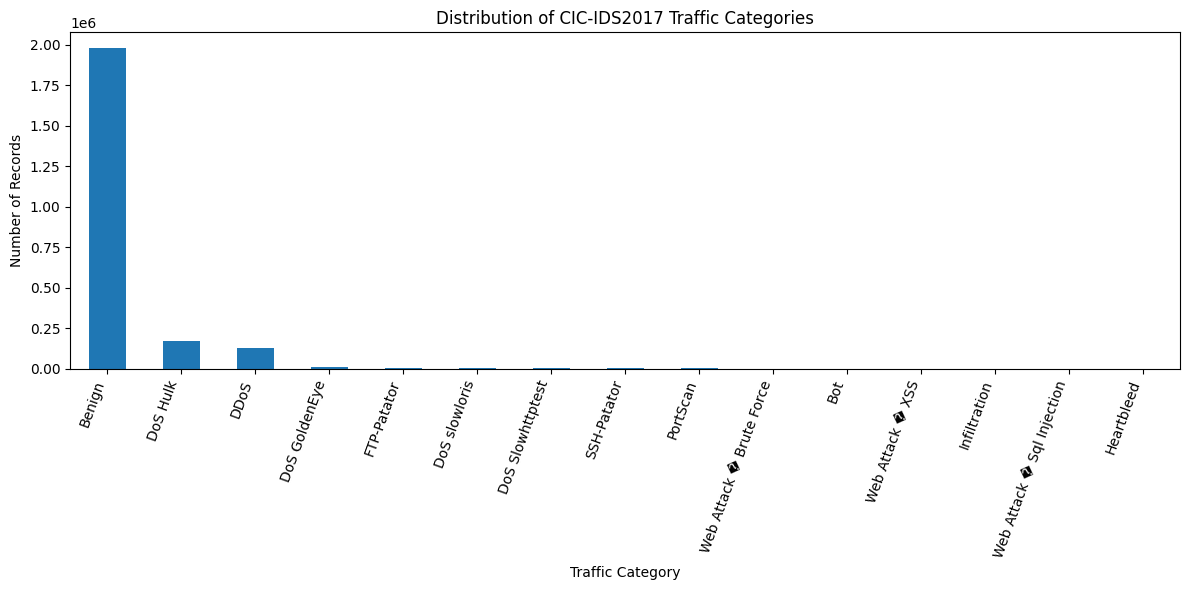

In [12]:
import matplotlib.pyplot as plt

label_counts = df[label_column].value_counts()

plt.figure(figsize=(12, 6))
label_counts.plot(kind="bar")

plt.title("Distribution of CIC-IDS2017 Traffic Categories")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

In [13]:
label_percentages = (
    df[label_column]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

display(
    label_percentages.to_frame("Percentage (%)")
)

,Percentage (%)
Label,
Benign,85.46
DoS Hulk,7.47
DDoS,5.53
DoS GoldenEye,0.44
FTP-Patator,0.26
DoS slowloris,0.23
DoS Slowhttptest,0.23
SSH-Patator,0.14
PortScan,0.08


In [14]:
missing_values = df.isnull().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary.to_frame("Missing values"))

No missing values found.


In [15]:
import numpy as np

numeric_columns = df.select_dtypes(include=np.number).columns

infinity_counts = np.isinf(
    df[numeric_columns].to_numpy()
).sum(axis=0)

infinity_summary = pd.Series(
    infinity_counts,
    index=numeric_columns
)

infinity_summary = infinity_summary[
    infinity_summary > 0
].sort_values(ascending=False)

if infinity_summary.empty:
    print("No infinite values found.")
else:
    display(infinity_summary.to_frame("Infinite values"))

No infinite values found.


In [16]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)
print("Total rows:", len(df))
print(
    "Duplicate percentage:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

Duplicate rows: 82004
Total rows: 2313810
Duplicate percentage: 3.54 %


In [17]:
print(df[label_column].value_counts().index.tolist())

['Benign', 'DoS Hulk', 'DDoS', 'DoS GoldenEye', 'FTP-Patator', 'DoS slowloris', 'DoS Slowhttptest', 'SSH-Patator', 'PortScan', 'Web Attack � Brute Force', 'Bot', 'Web Attack � XSS', 'Infiltration', 'Web Attack � Sql Injection', 'Heartbleed']


In [18]:
df[label_column] = df[label_column].astype("string").str.strip()

benign_labels = ["BENIGN", "Benign", "benign"]

df["Binary_Label"] = np.where(
    df[label_column].isin(benign_labels),
    "Benign",
    "Attack"
)

print(df["Binary_Label"].value_counts())

Binary_Label
Benign    1977318
Attack     336492
Name: count, dtype: int64


In [19]:
df["Multiclass_Label"] = df[label_column]

print("Number of classes:", df["Multiclass_Label"].nunique())
print("\nClass distribution:")
print(df["Multiclass_Label"].value_counts())

Number of classes: 15

Class distribution:
Multiclass_Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64


In [20]:
label_counts.to_csv(
    "cicids2017_label_distribution.csv",
    header=["Count"]
)

print("Label distribution saved.")

Label distribution saved.


In [21]:
from google.colab import files

files.download("cicids2017_label_distribution.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
print("Dataset shape:", df.shape)
print("\nLabel column:", label_column)
print("\nTraffic categories:")
print(df[label_column].value_counts())

print("\nBinary target:")
print(df["Binary_Label"].value_counts())

Dataset shape: (2313810, 80)

Label column: Label

Traffic categories:
Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64

Binary target:
Binary_Label
Benign    1977318
Attack     336492
Name: count, dtype: int64


In [23]:
model_df = df.copy()

# Remove records without a usable target
model_df = model_df.dropna(subset=[label_column]).copy()

print("Rows available for modelling:", len(model_df))
print("Number of traffic classes:", model_df[label_column].nunique())

Rows available for modelling: 2313810
Number of traffic classes: 15


In [24]:
print(model_df.dtypes.value_counts())

print("\nNon-numeric columns:")
print(
    model_df.select_dtypes(exclude=np.number).columns.tolist()
)

int32             26
float32           22
int8              19
int16              7
float64            2
string[python]     2
int64              1
object             1
Name: count, dtype: int64

Non-numeric columns:
['Label', 'Binary_Label', 'Multiclass_Label']


In [25]:
print("Potential identifier or timestamp columns:")

for column in model_df.columns:
    name = column.lower()

    if any(term in name for term in [
        "flow id", "source ip", "destination ip",
        "timestamp", "date", "time"
    ]):
        print(column)

Potential identifier or timestamp columns:


In [26]:
print(model_df["Binary_Label"].value_counts(dropna=False))
print("\nMissing binary targets:", model_df["Binary_Label"].isna().sum())

Binary_Label
Benign    1977318
Attack     336492
Name: count, dtype: int64

Missing binary targets: 0


In [27]:
target_column = "Binary_Label"

excluded_columns = {
    label_column,
    "Binary_Label",
    "Multiclass_Label"
}

for column in model_df.columns:
    name = column.lower()

    if any(term in name for term in [
        "flow id", "source ip", "destination ip", "timestamp"
    ]):
        excluded_columns.add(column)

X = model_df.drop(
    columns=[c for c in excluded_columns if c in model_df.columns]
)

X = X.select_dtypes(include=np.number).copy()

y = model_df[target_column].copy()

print("Number of input features:", X.shape[1])
print("Number of target records:", len(y))
print("\nFirst 10 feature names:")
print(X.columns.tolist()[:10])

Number of input features: 77
Number of target records: 2313810

First 10 feature names:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']


In [28]:
X = X.replace([np.inf, -np.inf], np.nan)

print("Feature matrix shape:", X.shape)
print("Infinite values remaining:", np.isinf(X.to_numpy()).sum())
print("Columns entirely missing:", X.columns[X.isna().all()].tolist())

Feature matrix shape: (2313810, 77)
Infinite values remaining: 0
Columns entirely missing: []


In [29]:
all_missing_columns = X.columns[X.isna().all()].tolist()

if all_missing_columns:
    X = X.drop(columns=all_missing_columns)

print("Features after removing entirely missing columns:", X.shape[1])

Features after removing entirely missing columns: 77


In [30]:
sample_size = min(100_000, len(model_df))

sample_fraction = sample_size / len(model_df)

sample_df = model_df.groupby(
    target_column, group_keys=False
).sample(
    frac=sample_fraction,
    random_state=42
)

X_sample = X.loc[sample_df.index]
y_sample = y.loc[sample_df.index]

print("Sample size:", len(X_sample))
print("\nClass distribution:")
print(y_sample.value_counts())

Sample size: 100000

Class distribution:
Binary_Label
Benign    85457
Attack    14543
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    random_state=42,
    stratify=y_sample
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 80000
Testing records: 20000

Training class distribution:
Binary_Label
Benign    0.855
Attack    0.145
Name: proportion, dtype: float64

Testing class distribution:
Binary_Label
Benign    0.855
Attack    0.145
Name: proportion, dtype: float64


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=300,
        class_weight="balanced",
        random_state=42
    ))
])

print("Baseline pipeline created.")

Baseline pipeline created.


In [33]:
import time

start_time = time.time()

baseline_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Model training completed!")
print("Training time:", round(training_time, 2), "seconds")

Model training completed!
Training time: 9.28 seconds


In [34]:
y_pred = baseline_model.predict(X_test)

print("Predictions completed.")
print("First 20 actual labels:")
print(y_test.iloc[:20].tolist())

print("\nFirst 20 predicted labels:")
print(y_pred[:20].tolist())

Predictions completed.
First 20 actual labels:
['Benign', 'Benign', 'Benign', 'Benign', 'Benign', 'Attack', 'Benign', 'Benign', 'Benign', 'Benign', 'Benign', 'Benign', 'Attack', 'Benign', 'Benign', 'Attack', 'Benign', 'Benign', 'Benign', 'Benign']

First 20 predicted labels:
['Benign', 'Benign', 'Benign', 'Benign', 'Benign', 'Attack', 'Benign', 'Benign', 'Attack', 'Attack', 'Benign', 'Benign', 'Attack', 'Benign', 'Benign', 'Attack', 'Benign', 'Benign', 'Benign', 'Benign']


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, pos_label="Attack", zero_division=0
)
recall = recall_score(
    y_test, y_pred, pos_label="Attack", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, pos_label="Attack", zero_division=0
)

print("BASELINE MODEL: LOGISTIC REGRESSION")
print("-----------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

BASELINE MODEL: LOGISTIC REGRESSION
-----------------------------------
Accuracy:  0.9362
Precision: 0.7056
Recall:    0.9625
F1-score:  0.8143

Detailed classification report:
              precision    recall  f1-score   support

      Attack       0.71      0.96      0.81      2909
      Benign       0.99      0.93      0.96     17091

    accuracy                           0.94     20000
   macro avg       0.85      0.95      0.89     20000
weighted avg       0.95      0.94      0.94     20000



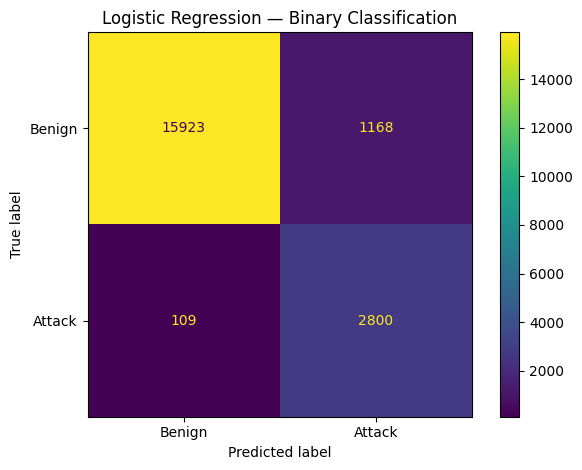

Confusion matrix:
[[15923  1168]
 [  109  2800]]


In [36]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Benign", "Attack"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Attack"]
)

display_matrix.plot()
plt.title("Logistic Regression — Binary Classification")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

In [37]:
results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Task": "Binary Classification",
    "Sample Size": len(X_sample),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Training Time (seconds)": training_time
}])

display(results)
results.to_csv("baseline_results.csv", index=False)

print("Results saved to baseline_results.csv")

,Model,Task,Sample Size,Accuracy,Precision,Recall,F1-score,Training Time (seconds)
0,Logistic Regression,Binary Classification,100000,0.93615,0.705645,0.96253,0.814309,9.281015


Results saved to baseline_results.csv


In [38]:
from google.colab import files

files.download("baseline_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)
print("Feature columns:", X_train.columns.tolist()[:10])

Training features: (80000, 77)
Testing features: (20000, 77)
Training labels: (80000,)
Testing labels: (20000,)
Feature columns: ['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']


In [40]:
%pip -q install xgboost

In [41]:
import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("All required model libraries are ready.")

All required model libraries are ready.


In [42]:
def evaluate_binary_model(name, model, X_train, X_test, y_train, y_test):
    start = time.time()
    model.fit(X_train, y_train)
    training_seconds = time.time() - start

    predictions = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=["Benign", "Attack"]
    ).ravel()

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="Attack", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="Attack", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, pos_label="Attack", zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, predictions),
        "FPR": fp / (fp + tn) if (fp + tn) else 0,
        "Training Time (seconds)": round(training_seconds, 2)
    }

    print(f"\n{name}")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    return metrics, model

In [43]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=500,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=20,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=20,
            class_weight="balanced",
            n_jobs=-1,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            tree_method="hist",
            eval_metric="logloss",
            n_jobs=2,
            random_state=42
        ))
    ]),

    "Linear SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearSVC(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ])
}

print("Five model pipelines created.")

Five model pipelines created.


In [44]:
comparison_results = []
trained_models = {}
failed_models = {}

for name, model in models.items():
    print("\n" + "=" * 55)
    print("Training:", name)

    try:
        metrics, fitted_model = evaluate_binary_model(
            name, model, X_train, X_test, y_train, y_test
        )

        comparison_results.append(metrics)
        trained_models[name] = fitted_model

    except Exception as error:
        failed_models[name] = str(error)
        print("This model failed:", error)

comparison_df = pd.DataFrame(comparison_results)

if not comparison_df.empty:
    comparison_df = comparison_df.sort_values(
        by="Macro-F1", ascending=False
    ).reset_index(drop=True)

    display(comparison_df)
else:
    print("No models completed successfully.")


Training: Logistic Regression

Logistic Regression
              precision    recall  f1-score   support

      Attack       0.71      0.96      0.81      2909
      Benign       0.99      0.93      0.96     17091

    accuracy                           0.94     20000
   macro avg       0.85      0.95      0.89     20000
weighted avg       0.95      0.94      0.94     20000


Training: Decision Tree

Decision Tree
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99      2909
      Benign       1.00      1.00      1.00     17091

    accuracy                           1.00     20000
   macro avg       0.99      1.00      0.99     20000
weighted avg       1.00      1.00      1.00     20000


Training: Random Forest

Random Forest
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99      2909
      Benign       1.00      1.00      1.00     17091

    accuracy                           1.00     20

,Model,Accuracy,Precision,Recall,F1-score,Macro-F1,MCC,FPR,Training Time (seconds)
0,Random Forest,0.99800,0.994485,0.991750,0.993115,0.995973,0.991947,0.000936,18.39
1,Decision Tree,0.99745,0.988714,0.993812,0.991257,0.994882,0.989768,0.001931,4.69
2,Logistic Regression,0.93615,0.705645,0.962530,0.814309,0.887878,0.790507,0.068340,7.47
3,Linear SVM,0.93125,0.686165,0.971812,0.804382,0.881339,0.781207,0.075654,27.21


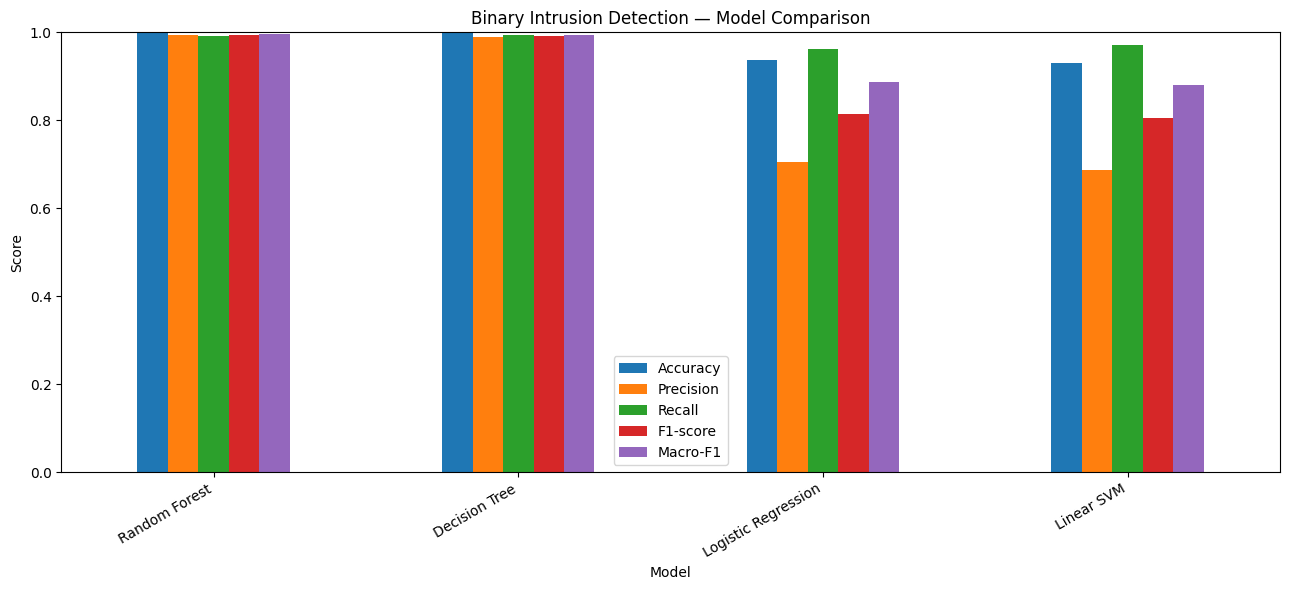

In [45]:
import matplotlib.pyplot as plt

if not comparison_df.empty:
    comparison_df.set_index("Model")[
        ["Accuracy", "Precision", "Recall", "F1-score", "Macro-F1"]
    ].plot(kind="bar", figsize=(13, 6))

    plt.title("Binary Intrusion Detection — Model Comparison")
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

In [46]:
comparison_df.to_csv(
    "binary_model_comparison.csv",
    index=False
)

print("Saved: binary_model_comparison.csv")

Saved: binary_model_comparison.csv


In [47]:
from google.colab import files

files.download("binary_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>